# 02 · NASA Moon Trek exploration

**Project:** Lunar Landing Site Navigator (NASA Space Apps 2026)

**Question:** what can the NASA Moon Trek layers give the app? We look at two uses:

* **basemap**: pictures shown under the site markers and Sun/Earth overlays.
* **quantitative data**: numbers such as % Earth visibility, % illumination and elevation, sampled at candidate landing sites.

Inputs: the catalog dumps and six south-polar mosaics in `data/raw/trek/`, made by `data/trek.py`. The mosaics are stitched from WMTS display PNGs.
Ephemeris for the cross-checks comes from `data/raw/horizons/` (notebook 01).

**TL;DR** (details in each section):

1. The Trek catalogs hold 1825 layers. About 25 south-pole layers matter to us: Earth visibility, sky visibility, illumination, PSRs, slope, DEMs and hillshades. Trek has **no time-resolved Sun or Earth product**. It only has long-term averages, so the app must still compute "where is the Sun right now" itself.
2. The WMTS tiles are 8-bit grayscale **display renderings**. For the layers we checked, gray is a plain linear stretch of the science value: Earth visibility is about 255 × fraction, and the Site01 DEM is about 0.1 gray per metre. You can get physical values back only by fitting against the raw file. The tiles themselves carry no scale metadata.
3. The raw science GeoTIFFs (Float32 / Byte) **can be downloaded** from `TrekWS/rest/cat/data/stream?label=<productLabel>`. This route is not in the connector. It always sends the whole file (no HTTP range support), and files run up to 244 MB at 240 m, or 3.7 GB for the 5 m slope mosaic.
4. The WMTS pyramids stop **1.7–4.5× coarser** than the native resolution. The PSR layer stops at 1070 m/px, but the native product is 240 m.
5. Georeferencing of the south-pole mosaics is correct to under one pixel: correlation is 0.9984 against raw Earth visibility and 0.99995 against the PGDA Site01 DEM. The connector's **equirectangular (EQ) pixel size is wrong by a factor of 3.67**, because Trek's EQ scale denominators use Earth's metres per degree.
6. Earth visibility changes a lot over a few km near the pole. The app should sample at the exact site and show local spread, not one number per region.

In [1]:
import io, json, sys, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import reproject
from pyproj import Transformer
import requests

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import data.trek as trek
from data.horizons import SITES

TREK = ROOT / "data" / "raw" / "trek"
SP = TREK / "sp"
HZ = ROOT / "data" / "raw" / "horizons"
STREAM = "https://trek.nasa.gov/moon/TrekWS/rest/cat/data/stream?label={}"
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "font.size": 9})

# lon/lat on the lunar sphere -> south polar stereographic metres (same PROJ string the connector writes)
to_sp = Transformer.from_crs(f"+proj=longlat +R={trek.R_MOON} +no_defs", trek.PROJ["sp"][2], always_xy=True)
def sp_xy(lat, lon):
    return to_sp.transform(lon, lat)

polar_sites = {k: v for k, v in SITES.items() if v[0] < -60}
print({k: tuple(round(c / 1000, 1) for c in sp_xy(*v)) for k, v in polar_sites.items()}, "(x, y km)")

{'site01_connecting_ridge': (-11.0, -12.0), 'site04_shackleton_rim': (-1.0, -7.1), 'im1_odysseus': (7.5, 299.9), 'chandrayaan3': (338.1, 534.4)} (x, y km)


## 1. Catalog overview

`search_layers(proj)` returns one record per product layer. We load all three projection catalogs into one table.

In [2]:
cat = pd.concat([pd.DataFrame(json.loads((TREK / f"catalog_{p}.json").read_text())).assign(proj=p)
                 for p in ("eq", "np", "sp")], ignore_index=True)
cat["resolution"] = pd.to_numeric(cat["resolution"], errors="coerce")
print(cat.groupby("proj").size().to_dict(), "layers;", len(cat.columns), "fields")
print("RASTER_TYPE by projection:")
display(pd.crosstab(cat["RASTER_TYPE"].fillna("(none: vector/feature)"), cat["proj"]))

{'eq': 1256, 'np': 173, 'sp': 396} layers; 32 fields
RASTER_TYPE by projection:


proj,eq,np,sp
RASTER_TYPE,,,
(none: vector/feature),22,8,23
colormap,50,6,7
grayscale,231,29,56
raw,346,83,167
rgb,410,45,141
rgba,197,2,2


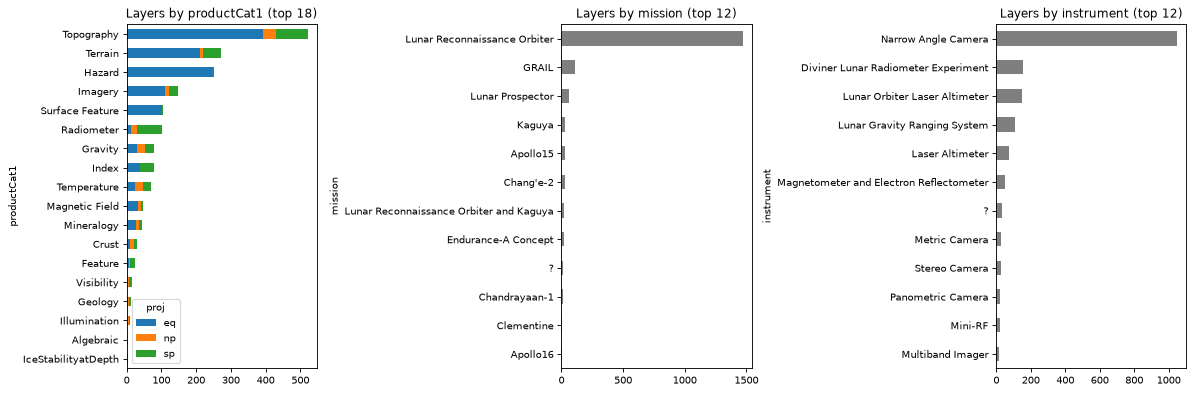

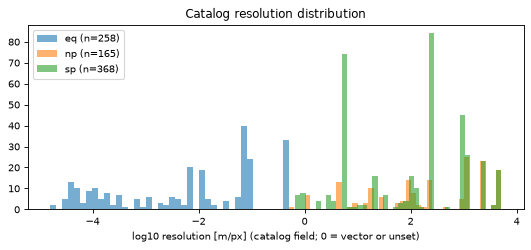

layers with resolution 0/missing: 1034


In [3]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
top = cat["productCat1"].value_counts().index[:18]
pd.crosstab(cat["productCat1"], cat["proj"]).loc[top[::-1]].plot.barh(stacked=True, ax=axs[0])
axs[0].set_title("Layers by productCat1 (top 18)")
cat["mission"].fillna("?").value_counts().head(12)[::-1].plot.barh(ax=axs[1], color="tab:gray")
axs[1].set_title("Layers by mission (top 12)")
cat["instrument"].fillna("?").value_counts().head(12)[::-1].plot.barh(ax=axs[2], color="tab:gray")
axs[2].set_title("Layers by instrument (top 12)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 3))
r = cat.loc[cat["resolution"] > 0]
for p, g in r.groupby("proj"):
    ax.hist(np.log10(g["resolution"]), bins=40, alpha=.6, label=f"{p} (n={len(g)})")
ax.set_xlabel("log10 resolution [m/px] (catalog field; 0 = vector or unset)")
ax.legend(); ax.set_title("Catalog resolution distribution"); plt.show()
print("layers with resolution 0/missing:", (~(cat["resolution"] > 0)).sum())

### Layers relevant to the app

We filter by category and by keywords in the title. These fields matter for the app:

* `RASTER_TYPE`: `raw` means the source is Float32 science data. `grayscale`/`rgb` means the source itself is an 8-bit picture.
* `serviceTypes`: `raster` shows that a raw GeoTIFF download is also offered.
* `bbox`: south-pole stereographic metres. A bbox of ±931 km reaches 60°S, ±152 km reaches 85°S, and ±76 km reaches 87.5°S.

In [4]:
rel_cat = {"Illumination", "Visibility", "Hazard"}
kw = r"Slope|DEM|Hillshade|Landing|Artemis|Illumin|Visib|Shadow|Station"
rel = cat[(cat["productCat1"].isin(rel_cat) | cat["title"].str.contains(kw, case=False))
          & ~cat["productCat2"].fillna("").str.contains("Colorized|Color", case=False)]
print("relevant (non-colorized) layers per projection:", rel.groupby("proj").size().to_dict())
print(rel.groupby(["proj", "productCat1"]).size().unstack(0).fillna(0).astype(int).to_string())
cols = ["productLabel", "title", "productCat2", "RASTER_TYPE", "PIXEL_DEPTH", "resolution", "serviceTypes", "bbox"]
sp_rel = rel[(rel.proj == "sp") & rel["productCat1"].isin(rel_cat | {"Feature"})]
with pd.option_context("display.max_colwidth", 60, "display.width", 250):
    display(sp_rel[cols].sort_values(["productCat2", "resolution"]))

relevant (non-colorized) layers per projection: {'eq': 486, 'np': 35, 'sp': 97}
proj           eq  np  sp
productCat1              
Feature         5   0   4
Hazard        147   1   1
Illumination    2   4   4
Imagery        12   0   3
Terrain        57   1  19
Topography    263  25  62
Visibility      0   4   4


,productLabel,title,productCat2,RASTER_TYPE,PIXEL_DEPTH,resolution,serviceTypes,bbox
1624,Diviner_avg_RockAbundance_SP,"LRO DLRE, Rock Abundance South Polar",Abundance,NaN,NaN,171.449429,[Mosaic],"-931069.854,-931042.395,931042.395,931069.854"
1592,AVGVISIB_85S_060M_201608_EARTH_SP,"LRO LOLA Average Earth Visibility, 60 mpp, S Pole",Earth,raw,Float32,60.000000,"[Mosaic, raster]","-151740,-151740,151740,151740"
1620,AVGVISIB_75S_120M_201608_EARTH_SP,"LRO LOLA Average Earth Visibility, 120 mpp, S Pole",Earth,raw,Float32,120.000000,"[Mosaic, raster]","-457440,-457440,457440,457440"
1705,AVGVISIB_65S_240M_201608_EARTH_SP,"LRO LOLA Average Earth Visibility, 240 mpp, S Pole",Earth,raw,Float32,240.000000,"[Mosaic, raster]","-931069.854,-931090.146,931090.146,931069.854"
1429,A3_Named_regions_SP,"Artemis III Candidate Landing Regions, S Pole",Landing Site,NaN,NaN,0.000000,"[Feature, Mosaic]","-123400,-66099.999,173999.999,132000"
1612,WAC_POLE_ILL_PCT_SOUTH_100M,"LRO WAC Percentage-Based Illumination 100mpp, S Pole",Percent Based,grayscale,Byte,100.000000,[Mosaic],"-60884.204,-61186.798,61115.796,61213.202"
1452,PSR_SP,"Permanently Shadowed Regions (PSRs), S Pole",Permanently Shadowed,NaN,NaN,0.000000,"[Feature, Mosaic]","-225749.127992,-223835.470959,230351.246041,233170.834478"
1644,LRO_LOLA_Illumination_SPole65S_240m,LOLA Permanently Shadowed Regions Southpole 240m,Permanently Shadowed,grayscale,Byte,240.000000,[Mosaic],"-770160,-770640,770640,770160"
1441,EnduranceA_Waypoints_SouthernTraverse_SP,"Endurance-A Concept Science Stations, Version 1",Science Station,NaN,NaN,0.000000,[Feature],"25411.758474,-888649.444998,356064.142704,-30235.45247"
1442,EnduranceA_Waypoints_SouthernTraverse_v2_SP,"Endurance-A Concept Science Stations, Version 2",Science Station,NaN,NaN,0.000000,"[Feature, Mosaic]","25411.758474,-888649.444998,356064.142704,-30235.45247"


In [5]:
# Is anything time-resolved (lighting for a given date)? List every Illumination/Visibility layer in all projections.
iv = cat[cat["productCat1"].isin(["Illumination", "Visibility"])]
with pd.option_context("display.max_colwidth", 70, "display.width", 200):
    display(iv[["proj", "productCat2", "title", "resolution"]].sort_values(["proj", "productCat2"]).reset_index(drop=True))

,proj,productCat2,title,resolution
0,eq,Permanently Shadowed,LOLA Permanently Shadowed Regions Northpole 240m,0.017441
1,eq,Permanently Shadowed,LOLA Permanently Shadowed Regions Southpole 240m,0.017441
2,np,Earth,"LRO LOLA Average Earth Visibility, 60 mpp, N Pole",60.000000
3,np,Earth,"LRO LOLA Average Earth Visibility, 120 mpp, N Pole",120.000000
4,np,Earth,"LRO LOLA Average Earth Visibility, 240 mpp, N Pole",240.000000
5,np,Earth Colorized,"LRO LOLA Color Average Earth Visibility, 60 mpp, N Pole",60.000000
6,np,Earth Colorized,"LRO LOLA Color Average Earth Visibility, 120 mpp, N Pole",120.000000
7,np,Earth Colorized,"LRO LOLA Color Average Earth Visibility, 240 mpp, N Pole",240.000000
8,np,Percent Based,"LRO WAC Percentage-Based Illumination 100mpp, N Pole",100.000000
9,np,Permanently Shadowed,"Permanently Shadowed Regions (PSRs), N Pole",0.000000


**Takeaways**

* The south-pole catalog holds the products the app needs: **Average Earth Visibility** (60/120/240 m), **Sky Visibility**, **WAC % illumination** and **time-weighted illumination** (88–90°S, 100 m), **PSR maps** (raster and vector), **LOLA slope / DEM / hillshade** (5 m inside 87.5°S, plus 5 m site DEMs for Site01/04/06/07/11/20/23, Haworth, Shoemaker, DM2), and **Artemis III candidate regions** (vector).
* Every illumination and visibility product is a **long-term average**: Earth visibility is averaged over 18.6 years, WAC illumination over one lunar year. None of them gives Sun or Earth geometry for a chosen date. The app's core feature (Sun and Earth vs the horizon for a date) must still come from ephemerides plus a local horizon (Horizons + DEM). Trek supplies context and validation targets.
* Each science layer has a **Colorized** twin with RGB output. These look good as basemaps, but turning their colors back into numbers would need the color ramp, and the catalog does not provide one.

## 2. WMTS practicalities

Tile URL template from `WMTSCapabilities.xml`. Note the double slash, which the server accepts:

`https://trek.nasa.gov/tiles/Moon/{EQ|NP|SP}/{layer}/1.0.0//{Style}/{TileMatrixSet}/{TileMatrix}/{TileRow}/{TileCol}.png` (some layers are `.jpg`), with `Style=default` and `TileMatrixSet=default028mm`.

* CRS: `urn:ogc:def:crs:IAU2000::30120` (south polar stereographic, sphere R = 1737.4 km). The capabilities file itself says `EPSG::0`.
* Tile grid: 256 px tiles with the top-left at (−1 095 930, +1 095 930) m. Zoom 0 is a 2×1 matrix with 8 561.95 m/px, and each zoom level halves the pixel size. Zoom 0 has one useful tile, because a single 256 px tile already covers ±1 095 930 m. The 2×1 shape is a leftover from the equirectangular layout.
* Below: the deepest zoom of each layer compared with its native resolution.

In [6]:
LAYERS = {  # local mosaics -> short name
    "AVGVISIB_65S_240M_201608_EARTH_SP": "Earth visibility (avg, 240 m)",
    "SKYV_65S_240M_SP": "Sky visibility (240 m)",
    "WAC_POLE_ILL_PCT_SOUTH_100M": "WAC % illumination (100 m)",
    "LRO_LOLA_Illumination_SPole65S_240m": "PSR mask (240 m)",
    "LRO_LOLA_Shade_SPole875_5mp_v04": "LOLA hillshade 87.5S (5 m)",
    "Site01_final_adj_5mpp_surf": "Site01 DEM (5 m)",
}
bycode = cat[cat.proj == "sp"].set_index("productLabel")
caps, rows = {}, []
for lyr in LAYERS:
    c = caps[lyr] = trek.capabilities(lyr, "sp")
    rows.append({"layer": lyr, "zooms": len(c["matrices"]), "max-zoom m/px": round(c["matrices"][-1]["pixel"], 1),
                 "native m/px": bycode.loc[lyr, "resolution"],
                 "ratio": round(c["matrices"][-1]["pixel"] / bycode.loc[lyr, "resolution"], 2),
                 "caps bbox (km)": tuple(round(v / 1000) for v in c["bbox"]),
                 "catalog bbox (km)": tuple(round(float(v) / 1000) for v in bycode.loc[lyr, "bbox"].split(","))})
display(pd.DataFrame(rows))
print(caps["Site01_final_adj_5mpp_surf"]["template"])

,layer,zooms,max-zoom m/px,native m/px,ratio,caps bbox (km),catalog bbox (km)
0,AVGVISIB_65S_240M_201608_EARTH_SP,5,535.1,240.0,2.23,"(-772, -774, 773, 771)","(-931, -931, 931, 931)"
1,SKYV_65S_240M_SP,5,535.1,240.0,2.23,"(-931, -931, 931, 931)","(-931, -931, 931, 931)"
2,WAC_POLE_ILL_PCT_SOUTH_100M,6,267.6,100.0,2.68,"(-61, -61, 61, 61)","(-61, -61, 61, 61)"
3,LRO_LOLA_Illumination_SPole65S_240m,4,1070.2,240.0,4.46,"(-770, -771, 771, 770)","(-770, -771, 771, 770)"
4,LRO_LOLA_Shade_SPole875_5mp_v04,10,16.7,5.0,3.34,"(-76, -76, 76, 76)","(-76, -76, 76, 76)"
5,Site01_final_adj_5mpp_surf,11,8.4,5.0,1.67,"(-19, -20, -3, -4)","(-19, -20, -3, -4)"


https://trek.nasa.gov/tiles/Moon/SP/Site01_final_adj_5mpp_surf/1.0.0//{Style}/{TileMatrixSet}/{TileMatrix}/{TileRow}/{TileCol}.png


* **No WMTS level reaches native resolution.** The best levels are 8.4 m for the 5 m DEMs and 16.7 m for the 87.5°S hillshade. The PSR mask is the worst case: 1070 m/px against a 240 m product. For a basemap this is fine. Point sampling, however, picks up resampling blur.
* For `AVGVISIB_65S`, the capabilities bbox (±772 km, about 65°S) is smaller than the catalog/raw bbox (±931 km, 60°S). `mosaic()` uses the capabilities bbox, so the 60–65°S ring is cut off. Chandrayaan-3 (69.4°S) is still covered.

In [7]:
# Connector check, equirectangular: compare pixel size from ScaleDenominator with the geometric size 360 deg / (cols*256)
c = trek.capabilities("LRO_WAC_Mosaic_Global_303ppd_v02", "eq")
eq = pd.DataFrame([{"zoom": m["id"], "connector pixel [deg]": m["pixel"], "geometric 360/(cols*256)": 360 / (m["cols"] * m["tile"])}
                   for m in c["matrices"]])
eq["ratio"] = eq.iloc[:, 1] / eq.iloc[:, 2]
display(eq.head(4))
print("Earth m/deg / Moon m/deg =", 111319.49079 / (2 * math.pi * trek.R_MOON / 360))

,zoom,connector pixel [deg],geometric 360/(cols*256),ratio
0,0,2.578334,0.703125,3.666965
1,1,1.289167,0.351562,3.666965
2,2,0.644584,0.175781,3.666965
3,3,0.322292,0.087891,3.666965


Earth m/deg / Moon m/deg = 3.6710815009856326


**Connector bug (EQ only):** Trek's equirectangular `ScaleDenominator`s use Earth's 111 319.49 m per degree, the usual GoogleCRS84Quad convention. They do not use the Moon's 30 323.6 m/deg. `capabilities(..., "eq")` divides by the lunar value, so every EQ pixel size comes out **3.67× too large**. As a result, `mosaic(..., "eq")` would pick the wrong zoom and write a wrong geotransform. Fix: `pixel = 360 / (MatrixWidth * TileWidth)`, or use `m_per_unit = 111319.49079`. We do not touch `data/`, so this is only reported here. Polar projections are not affected, as section 3 confirms.

## 3. The south-pole mosaics on a map

The mosaics are RGBA. For every layer we checked, R = G = B (grayscale), and alpha marks coverage. Each one is shown on its true stereographic extent. Overlays: a lat/lon graticule (latitude circles, longitude spokes; 0°E points up, 90°E points right), the pole, and the polar sites from `data.horizons.SITES`.

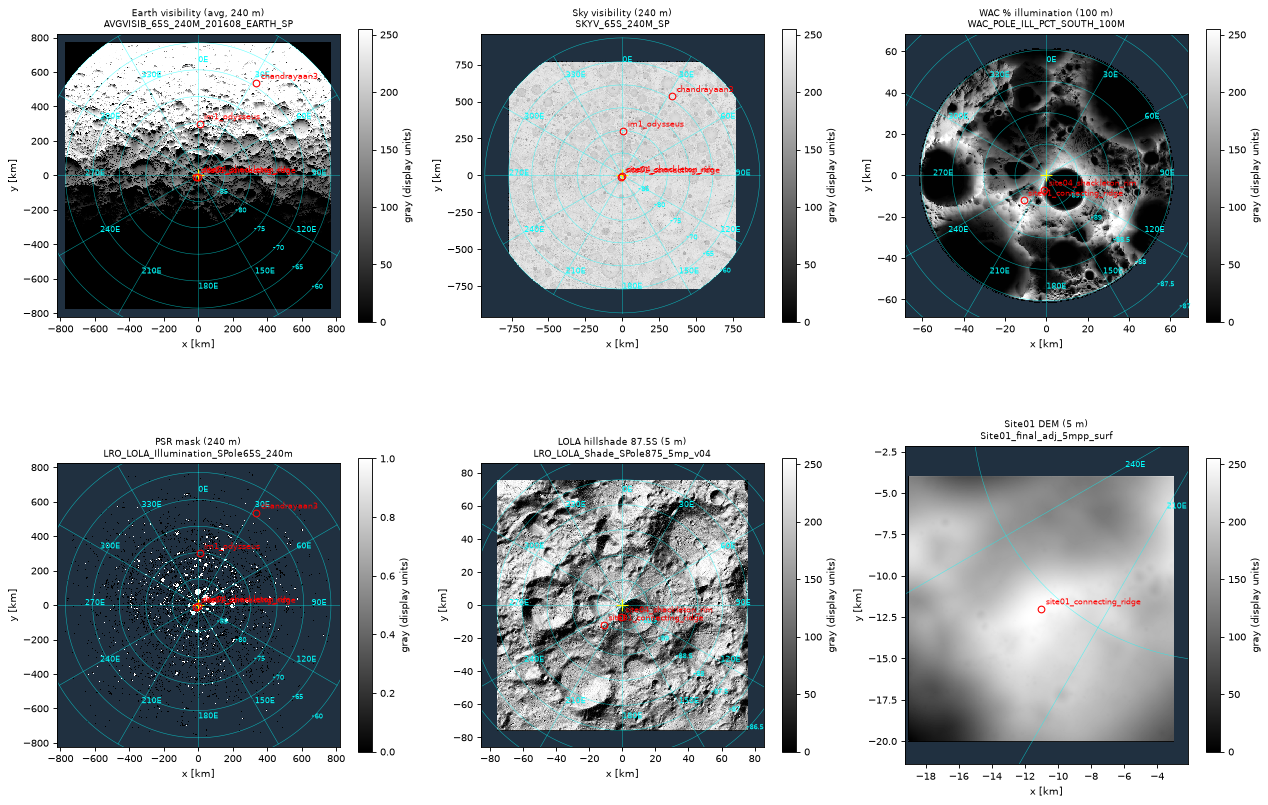

In [8]:
def load(lyr, max_px=900):
    # Display-sized read: decimate with rasterio, never load full res just to plot
    with rasterio.open(SP / f"{lyr}.tif") as ds:
        f = max(1, math.ceil(max(ds.width, ds.height) / max_px))
        a = ds.read(out_shape=(4, ds.height // f, ds.width // f), resampling=Resampling.nearest)
        b = ds.bounds
    return a, (b.left / 1e3, b.right / 1e3, b.bottom / 1e3, b.top / 1e3)

def graticule(ax, ext, lat_step=5):
    # latitude circles every lat_step deg (labelled), longitude spokes every 30 deg (labelled near the window edge)
    th = np.linspace(0, 360, 721)
    for lat in np.arange(-90 + lat_step, -59.9, lat_step):
        x, y = sp_xy(np.full_like(th, lat), th)
        ax.plot(np.array(x) / 1e3, np.array(y) / 1e3, lw=.5, color="cyan", alpha=.6)
        lx, ly = (v / 1e3 for v in sp_xy(lat, 135))
        if ext[0] < lx < ext[1] and ext[2] < ly < ext[3]:
            ax.text(lx, ly, f"{lat:g}", color="cyan", fontsize=6)
    r_lab = 0.8 * min(ext[1] - ext[0], ext[3] - ext[2]) / 2 * 1e3
    lat_lab = math.degrees(2 * math.atan(r_lab / (2 * trek.R_MOON))) - 90
    for lon in range(0, 360, 30):
        x, y = sp_xy(np.array([-90, -60]), np.array([lon, lon]))
        ax.plot(np.array(x) / 1e3, np.array(y) / 1e3, lw=.5, color="cyan", alpha=.6)
        lx, ly = (v / 1e3 for v in sp_xy(lat_lab, lon))
        ax.text(lx, ly, f"{lon}E", color="cyan", fontsize=7, clip_on=True)
    ax.set_xlim(ext[:2]); ax.set_ylim(ext[2:])

def sites(ax, ext, color="red"):
    ax.plot(0, 0, "+", color="yellow", ms=10)
    for k, (lat, lon) in polar_sites.items():
        x, y = (v / 1e3 for v in sp_xy(lat, lon))
        if ext[0] < x < ext[1] and ext[2] < y < ext[3]:
            ax.plot(x, y, "o", mfc="none", color=color, ms=6)
            ax.annotate(k, (x, y), xytext=(4, 4), textcoords="offset points", color=color, fontsize=7)

fig, axs = plt.subplots(2, 3, figsize=(16, 11))
for ax, (lyr, name) in zip(axs.flat, LAYERS.items()):
    a, ext = load(lyr)
    img = np.ma.masked_where(a[3] == 0, a[0])
    vmax = 1 if lyr.startswith("LRO_LOLA_Illumination") else 255
    im = ax.imshow(img, extent=ext, cmap="gray", vmin=0, vmax=vmax, interpolation="nearest")
    ax.set_facecolor("#203040")
    graticule(ax, ext, lat_step=5 if ext[1] > 300 else 0.5)
    sites(ax, ext)
    ax.set_title(f"{name}\n{lyr}", fontsize=8); ax.set_xlabel("x [km]"); ax.set_ylabel("y [km]")
    plt.colorbar(im, ax=ax, shrink=.7, label="gray (display units)")
plt.tight_layout(); plt.show()

Notes on the maps:

* The 240 m layers reach about 65°S (Earth visibility, PSR) or 60°S (sky visibility). The WAC illumination product covers only **88–90°S**, about a 61 km radius. The 87.5°S hillshade covers a ±76 km box. Of our sites, only Site01 and Site04 fall inside the WAC map. IM-1 at 80°S is not covered by it.
* In the PSR mask, gray is a constant 1 and the **alpha channel is the mask** (alpha = 0 where a pixel is not PSR or has no data). It also arrives at only 1070 m/px. The vector `PSR_SP` layer (a GeoJSON/zip download) is better suited as an overlay.
* Site01 and Site04 sit within about 16 km of the pole, so in the 240 m layers they cover just a few pixels.

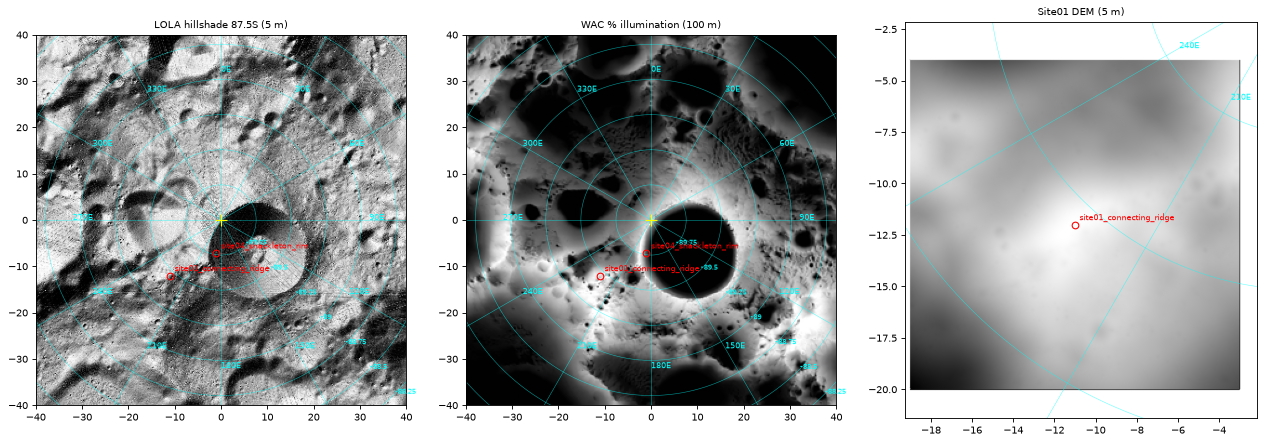

In [9]:
# Zoom on the pole: hillshade + WAC illumination + Site01 DEM with fine graticule
fig, axs = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, lyr, win in [(axs[0], "LRO_LOLA_Shade_SPole875_5mp_v04", (-40, 40, -40, 40)),
                     (axs[1], "WAC_POLE_ILL_PCT_SOUTH_100M", (-40, 40, -40, 40)),
                     (axs[2], "Site01_final_adj_5mpp_surf", None)]:
    a, ext = load(lyr, 1200)
    win = win or ext
    ax.imshow(np.ma.masked_where(a[3] == 0, a[0]), extent=ext, cmap="gray", vmin=0, vmax=255)
    graticule(ax, win, lat_step=0.25); sites(ax, win); ax.set_title(LAYERS[lyr], fontsize=9)
plt.tight_layout(); plt.show()

### Extra layers fetched for context

* `LRO_WAC_Mosaic_SPole60_100m_v02`: WAC image mosaic down to 60°S. This is the natural **imagery basemap** for south-pole sites outside 87.5°S, such as IM-1 and Chandrayaan-3. The mosaic is fetched through `trek.mosaic()` at ~2000 px (zoom 3, 1070 m/px) and cached in `data/raw/trek/sp/`.
* `AVGVISIB_85S_060M_201608_EARTH_SP`: the same Earth-visibility product at 60 m inside 85°S. The WMTS gives 134 m at most.
* **Artemis III candidate regions** (`A3_Named_regions_SP`). This is a vector layer and has no WMTS tiles (capabilities return 404). It comes as **GeoJSON in lon/lat** from the `data/stream` endpoint (3.5 kB), loaded here in memory.

In [10]:
EXTRA = {"LRO_WAC_Mosaic_SPole60_100m_v02": 2000, "AVGVISIB_85S_060M_201608_EARTH_SP": 2048}
for lyr, px in EXTRA.items():
    if not (SP / f"{lyr}.tif").exists():
        print("fetching", trek.mosaic(lyr, "sp", px))
    with rasterio.open(SP / f"{lyr}.tif") as ds:
        print(lyr, ds.width, "x", ds.height, "px at", round(ds.res[0], 1), "m/px")

a3 = requests.get(STREAM.format("A3_Named_regions_SP"), timeout=60).json()
print(len(a3["features"]), "Artemis III regions:", [f["properties"]["label"] for f in a3["features"]])

LRO_WAC_Mosaic_SPole60_100m_v02 2048 x 2048 px at 1070.2 m/px
AVGVISIB_85S_060M_201608_EARTH_SP 2560 x 2560 px at 133.8 m/px
13 Artemis III regions: ['Amundsen Rim', 'Nobile Rim 2', 'Haworth', 'Faustini Rim A', 'de Gerlache Rim 2', 'Connecting Ridge Extension', 'Connecting Ridge', 'Nobile Rim 1', 'Peak Near Shakleton', 'de Gerlache Rim', 'Leibnitz Beta Plateau', 'Malapert Massif', 'de Gerlache-Kocher Massif']


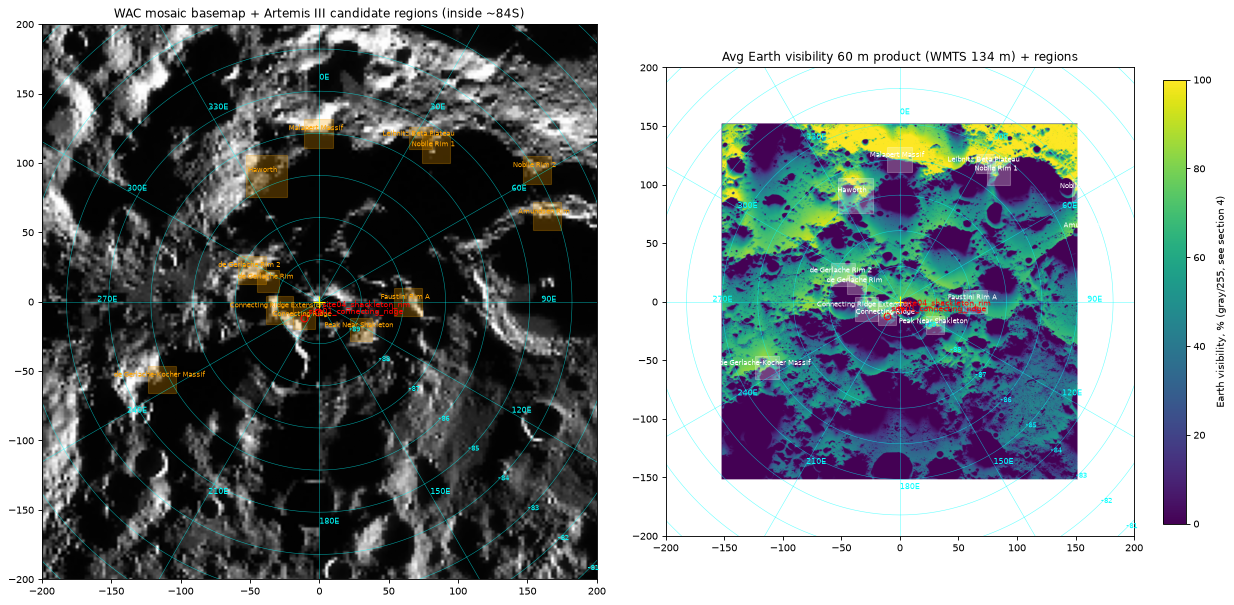

In [11]:
def draw_regions(ax, color="orange"):
    for f in a3["features"]:
        lon, lat = np.array(f["geometry"]["coordinates"][0]).T
        x, y = sp_xy(lat, lon)
        x, y = np.array(x) / 1e3, np.array(y) / 1e3
        ax.fill(x, y, fc=color, alpha=.25, ec=color, lw=1)
        ax.text(x.mean(), y.mean(), f["properties"]["label"], color=color, fontsize=6, ha="center")

fig, axs = plt.subplots(1, 2, figsize=(16, 7.5))
a, ext = load("LRO_WAC_Mosaic_SPole60_100m_v02", 1600)
win = (-200, 200, -200, 200)
axs[0].imshow(np.ma.masked_where(a[3] == 0, a[0]), extent=ext, cmap="gray")
draw_regions(axs[0]); graticule(axs[0], win, lat_step=1); sites(axs[0], win)
axs[0].set_title("WAC mosaic basemap + Artemis III candidate regions (inside ~84S)")
a, ext = load("AVGVISIB_85S_060M_201608_EARTH_SP", 1600)
im = axs[1].imshow(np.ma.masked_where(a[3] == 0, a[0] / 255 * 100), extent=ext, cmap="viridis", vmin=0, vmax=100)
draw_regions(axs[1], "white"); graticule(axs[1], win, lat_step=1); sites(axs[1], win, "red")
plt.colorbar(im, ax=axs[1], shrink=.8, label="Earth visibility, % (gray/255, see section 4)")
axs[1].set_title("Avg Earth visibility 60 m product (WMTS 134 m) + regions")
plt.tight_layout(); plt.show()

The regions are drawn in the right places. Connecting Ridge (Site01) and Peak near Shackleton fall inside their regions, so Trek's lon/lat vector data agrees with our stereographic transform. Note that the regions **facing the nearside (around 0°E, top half)** are bright in Earth visibility. The regions facing the farside (around 180°E, bottom) are dark. This is why Earth comms windows vary so much from region to region.

## 4. Can gray values be mapped back to physical values?

First the band statistics of the stored mosaics, then a direct comparison against the **raw science files**.

In [12]:
rows = []
for lyr in list(LAYERS) + list(EXTRA):
    with rasterio.open(SP / f"{lyr}.tif") as ds:
        a = ds.read()
    m = a[3] == 255
    g = a[0][m]
    rows.append({"layer": lyr, "px": a.shape[1] * a.shape[2], "% opaque": round(100 * m.mean(), 1),
                 "R=G=B": bool((a[0] == a[1]).all() and (a[1] == a[2]).all()),
                 "gray min": g.min(), "gray max": g.max(), "gray mean": round(g.mean(), 1),
                 "unique gray": len(np.unique(g)), "alpha levels": len(np.unique(a[3]))})
display(pd.DataFrame(rows))

,layer,px,% opaque,R=G=B,gray min,gray max,gray mean,unique gray,alpha levels
0,AVGVISIB_65S_240M_201608_EARTH_SP,9437184,88.2,True,0,255,97.6,256,23
1,SKYV_65S_240M_SP,12845056,61.5,True,0,255,216.4,207,254
2,WAC_POLE_ILL_PCT_SOUTH_100M,262144,61.5,True,0,255,65.3,256,238
3,LRO_LOLA_Illumination_SPole65S_240m,2359296,0.5,True,1,1,1.0,1,256
4,LRO_LOLA_Shade_SPole875_5mp_v04,6553600,78.3,True,0,255,147.3,256,20
5,Site01_final_adj_5mpp_surf,4718592,77.6,True,1,255,171.5,255,35
6,LRO_WAC_Mosaic_SPole60_100m_v02,4194304,78.3,True,0,255,83.6,256,256
7,AVGVISIB_85S_060M_201608_EARTH_SP,6553600,78.4,True,0,255,85.9,256,11


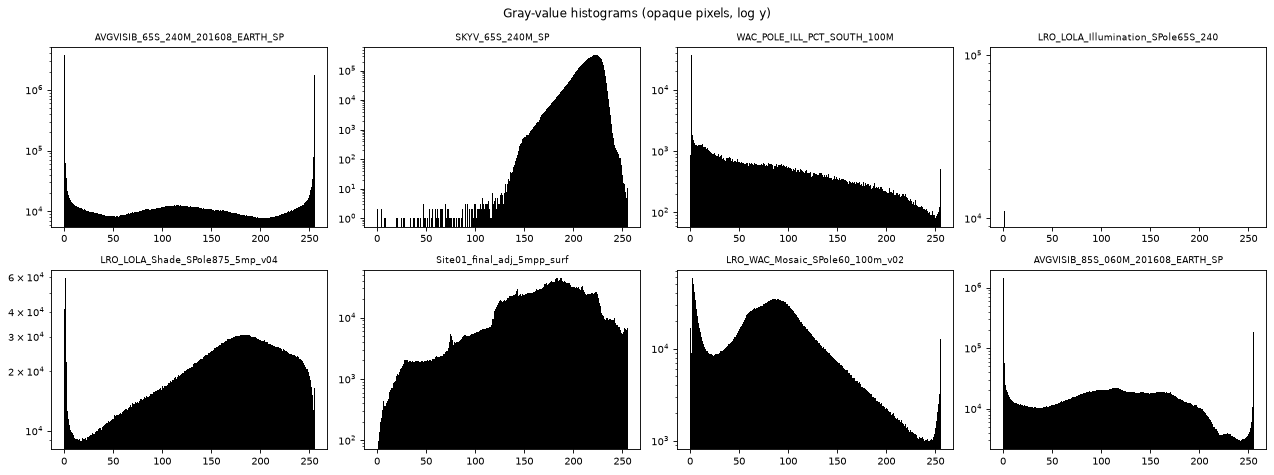

In [13]:
fig, axs = plt.subplots(2, 4, figsize=(16, 6))
for ax, lyr in zip(axs.flat, list(LAYERS) + list(EXTRA)):
    with rasterio.open(SP / f"{lyr}.tif") as ds:
        a = ds.read([1, 4])
    ax.hist(a[0][a[1] == 255], bins=np.arange(257) - .5, color="k", log=True)
    ax.set_title(lyr[:34], fontsize=8)
plt.suptitle("Gray-value histograms (opaque pixels, log y)"); plt.tight_layout(); plt.show()

* All 8-bit PNG tiles come as grayscale+alpha (`LA`). The connector turns them into RGBA, so R = G = B.
* Earth visibility uses the full 0–255 range, with large spikes at 0 (no Earth) and 255 (Earth always above the terrain). This is what you would expect from a fraction stretched to 0–255.
* The PSR layer has gray = 1 everywhere it is opaque. The information is in **alpha** (0–255, antialiased by downsampling), which is the PSR mask (0.5 % of the mosaic).
* **The tiles carry no scale or offset.** The layer abstracts (`TrekWS/rest/cat/abstract?label=…`) give units only. They say "percentage of Earth visibility" or "steradians", and nothing about the stretch.

### Ground truth: the raw GeoTIFF download

The `data/stream` endpoint returns the original science file for raster layers. It needs no authentication, but it **always sends the whole file**, because it ignores `Range` headers. Below we download the 244 MB raw Earth-visibility file **into memory** (about 10 s here), plus the 1.6 MB raw WAC illumination file. We reproject each one onto the mosaic grid and compare.

In [14]:
def raw(label):
    r = requests.get(STREAM.format(label), timeout=600)
    r.raise_for_status()
    return rasterio.open(io.BytesIO(r.content))  # rasterio keeps the in-memory file alive with the dataset

def on_mosaic_grid(src, lyr):
    # Average-resample a raw raster onto the mosaic's grid -> (raw, gray, alpha)
    with rasterio.open(SP / f"{lyr}.tif") as m:
        g, al = m.read(1).astype(float), m.read(4)
        dst = np.full(g.shape, np.nan, np.float32)
        reproject(rasterio.band(src, 1), dst, src_nodata=src.nodata, dst_nodata=np.nan,
                  dst_transform=m.transform, dst_crs=m.crs, resampling=Resampling.average)
    return dst.astype(float), g, al

ev_raw = raw("AVGVISIB_65S_240M_201608_EARTH_SP")
print(ev_raw.profile["dtype"], ev_raw.shape, ev_raw.res, "nodata", ev_raw.nodata)
v = ev_raw.read(1, masked=True)
print("raw value range:", float(v.min()), "-", float(v.max()), " -> stored as a FRACTION 0-1, not percent as the abstract says")

float32 (7759, 7759) (240.0, 240.0) nodata -3.4028234663852886e+38


raw value range: 0.0 - 1.0  -> stored as a FRACTION 0-1, not percent as the abstract says


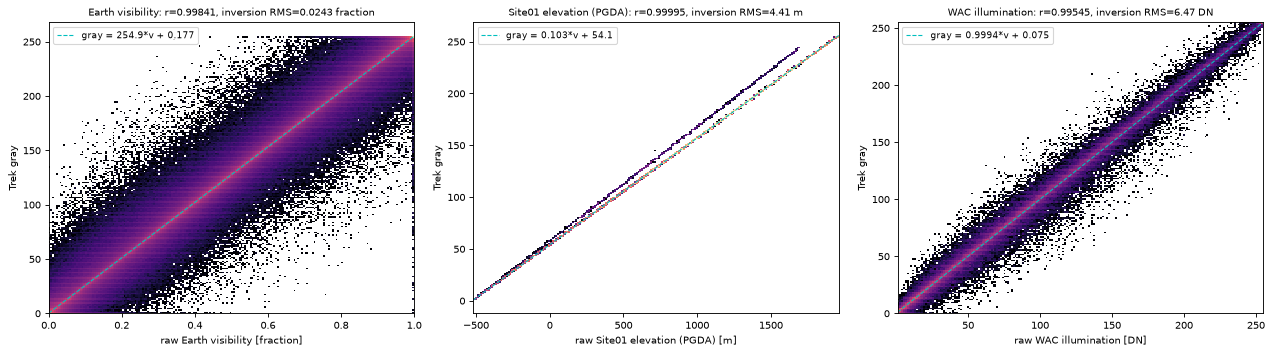

Earth vis  slope 254.93 gray/unit, offset 0.177 gray; 95% abs inversion error 0.0444
Site01 DEM slope 0.103 gray/unit, offset 54.1 gray; 95% abs inversion error 6.12
WAC        slope 0.99943 gray/unit, offset 0.075 gray; 95% abs inversion error 13.9
Site01 DEM: implied stretch range -525 to 1950 m


In [15]:
def calib(x, y, name, unit, ax):
    ok = np.isfinite(x)
    x, y = x[ok], y[ok]
    slope, icpt = np.polyfit(x, y, 1)
    inv = (y - icpt) / slope   # gray -> physical
    err = inv - x
    ax.hist2d(x, y, bins=200, cmap="magma", norm="log")
    xx = np.linspace(x.min(), x.max(), 2)
    ax.plot(xx, slope * xx + icpt, "c--", lw=1, label=f"gray = {slope:.4g}*v + {icpt:.3g}")
    ax.set_xlabel(f"raw {name} [{unit}]"); ax.set_ylabel("Trek gray"); ax.legend(fontsize=8)
    r = np.corrcoef(x, y)[0, 1]
    ax.set_title(f"{name}: r={r:.5f}, inversion RMS={err.std():.3g} {unit}", fontsize=9)
    return slope, icpt, err

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
x, g, al = on_mosaic_grid(ev_raw, "AVGVISIB_65S_240M_201608_EARTH_SP")
ev_fit = calib(x[al == 255], g[al == 255], "Earth visibility", "fraction", axs[0])

with rasterio.open(ROOT / "data/raw/pgda/Site01/Site01_final_adj_5mpp_surf.tif") as dem:
    x, g, al = on_mosaic_grid(dem, "Site01_final_adj_5mpp_surf")
dem_fit = calib(x[al == 255], g[al == 255], "Site01 elevation (PGDA)", "m", axs[1])

wac_raw = raw("WAC_POLE_ILL_PCT_SOUTH_100M")
x, g, al = on_mosaic_grid(wac_raw, "WAC_POLE_ILL_PCT_SOUTH_100M")
wac_fit = calib(x[al == 255], g[al == 255], "WAC illumination", "DN", axs[2])
plt.tight_layout(); plt.show()
for n, (s, i, e) in {"Earth vis": ev_fit, "Site01 DEM": dem_fit, "WAC": wac_fit}.items():
    print(f"{n:10s} slope {s:.5g} gray/unit, offset {i:.3g} gray; 95% abs inversion error {np.percentile(abs(e), 95):.3g}")
print("Site01 DEM: implied stretch range", round(-dem_fit[1] / dem_fit[0]), "to", round((255 - dem_fit[1]) / dem_fit[0]), "m")

**Result: the gray values are linear stretches, so you can invert them, but only with an outside calibration.**

| layer | mapping | 1 gray step is | inversion error* |
|---|---|---|---|
| Earth visibility | gray ≈ 254.9 × fraction + 0.2 | 0.4 % visibility | RMS 2.4 %, 95 % < 4.4 % (mostly from resampling 240 m → 535 m) |
| Site01 DEM | linear min–max stretch over the layer's elevation range (≈ −525 … 1950 m) | ~9.7 m | RMS 4.4 m, 95 % < 6.1 m (8-bit quantisation + 5 m → 8.4 m resampling) |
| WAC illumination | gray ≈ raw DN (Byte → Byte) | 1 DN | RMS 6.5 DN, 95 % < 14 DN (100 m → 268 m on steep lighting gradients) |

\*from the fits above, at the WMTS's coarsest-but-best zoom.

* For **Earth visibility**, `gray/255` is a good proxy at screen scale. For numbers we report, use the raw Float32 file instead.
* For **DEMs**, the stretch range is unknown for any other site, and ~10 m steps make slope or horizon calculations useless. **Never derive topography from Trek tiles.** Use PGDA/LOLA float DEMs (notebook 03).
* About 0.1 % of DEM pixels lie on a second line 5–15 gray above the fit (visible in the middle panel). They are scattered and not on tile seams. The likely cause is a small difference between the Trek copy and the PGDA file. This is one more reason to treat tiles as pictures.
* The raw **WAC** product is itself 8-bit (DN 1–255, 0 = nodata). Its percent scaling is not documented. `DN/255 × 100` is the natural reading. However, 0.5 % of valid pixels sit at exactly 255, which would mean "100 % lit". That is not physically plausible near the pole (Speyerer & Robinson 2013 report peaks around 90 %), so treat 255 as saturated or flagged.

WAC raw DN: valid px 1166572, at 255: 0.51%, 99th percentile below 255: 237


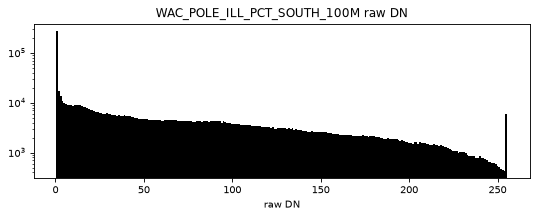

In [16]:
wa = wac_raw.read(1)
valid = wa[wa > 0]
print(f"WAC raw DN: valid px {valid.size}, at 255: {(valid == 255).mean():.2%}, 99th percentile below 255: "
      f"{np.percentile(valid[valid < 255], 99):.0f}")
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.hist(valid, bins=np.arange(1, 257) - .5, log=True, color="k"); ax.set_xlabel("raw DN"); ax.set_title("WAC_POLE_ILL_PCT_SOUTH_100M raw DN")
plt.show()

## 5. Sampling candidate sites

For every polar site we sample:

* Earth visibility from the raw file (exact) and from the tile gray (gray/255).
* WAC illumination (raw DN/255) and the PSR flag.
* For comparison, the **Horizons 2026 hourly ephemeris** (notebook 01): the fraction of hours with Earth (or Sun) elevation > 0° above a **flat** horizon. The gap between the two shows how much **terrain** blocks.

For context we also give the spread (5th–95th percentile) of raw Earth visibility within 2 km of each site.

In [17]:
def sample(src, x, y, band=1):
    v = next(src.sample([(x, y)], indexes=band))[0]
    return np.nan if src.nodata is not None and v == src.nodata else float(v)

def sample_mosaic(lyr, x, y):
    with rasterio.open(SP / f"{lyr}.tif") as ds:
        g, a = (float(v) for v in next(ds.sample([(x, y)], indexes=[1, 4])))
    return g if a > 0 else np.nan

def psr(x, y):
    with rasterio.open(SP / "LRO_LOLA_Illumination_SPole65S_240m.tif") as ds:
        return bool(next(ds.sample([(x, y)], indexes=4))[0] > 0)

def spread(src, x, y, r=2000):
    win = rasterio.windows.from_bounds(x - r, y - r, x + r, y + r, src.transform)
    a = src.read(1, window=win, masked=True).compressed()
    return np.percentile(a, [5, 95]) if a.size else (np.nan, np.nan)

def flat_frac(site, body):
    p = HZ / f"{site}_{body}.csv"
    return (pd.read_csv(p)["el_deg"] > 0).mean() if p.exists() else np.nan

rows = []
for k, (lat, lon) in polar_sites.items():
    x, y = sp_xy(lat, lon)
    lo, hi = spread(ev_raw, x, y)
    rows.append({"site": k, "lat": lat, "lon_E": lon, "dist pole km": round(math.hypot(x, y) / 1e3, 1),
                 "EarthVis raw %": 100 * sample(ev_raw, x, y),
                 "EarthVis tile % (gray/255)": 100 * sample_mosaic("AVGVISIB_65S_240M_201608_EARTH_SP", x, y) / 255,
                 "EarthVis 60m tile %": 100 * sample_mosaic("AVGVISIB_85S_060M_201608_EARTH_SP", x, y) / 255,
                 "EarthVis raw 2km p5-p95 %": f"{100*lo:.0f}-{100*hi:.0f}",
                 "Earth above flat horizon 2026 %": 100 * flat_frac(k, "earth"),
                 "WAC illum % (DN/255)": 100 * sample(wac_raw, x, y) / 255,
                 "Sun above flat horizon 2026 %": 100 * flat_frac(k, "sun"),
                 "PSR (tile alpha>0)": psr(x, y),
                 "SkyVis gray": sample_mosaic("SKYV_65S_240M_SP", x, y)})
site_tbl = pd.DataFrame(rows).set_index("site")
display(site_tbl.round(1))

,lat,lon_E,dist pole km,EarthVis raw %,EarthVis tile % (gray/255),EarthVis 60m tile %,EarthVis raw 2km p5-p95 %,Earth above flat horizon 2026 %,WAC illum % (DN/255),Sun above flat horizon 2026 %,PSR (tile alpha>0),SkyVis gray
site,,,,,,,,,,,,
site01_connecting_ridge,-89.5,222.5,16.3,54.4,58.4,67.1,0-58,44.0,89.0,52.5,False,239.0
site04_shackleton_rim,-89.8,188.0,7.2,10.7,9.8,17.3,0-50,44.7,33.3,49.8,False,186.0
im1_odysseus,-80.1,1.4,300.0,100.0,100.0,NaN,77-100,100.0,NaN,51.5,False,216.0
chandrayaan3,-69.4,32.3,632.3,100.0,100.0,NaN,100-100,100.0,NaN,50.7,False,231.0


How to read the table:

* **Raw values and tile values agree** within about 4 points: Site01 54 % raw vs 58 % from the tile, Site04 11 % vs 10 %. The 60 m product gives higher values at both (67 %, 17 %), because a 240 m pixel averages a ridge crest with its shadowed flanks.
* **Terrain matters.** The flat-horizon Earth fraction from Horizons is only geometry: libration moves Earth up and down by about ±7° around the horizon at the pole. The Trek value includes local relief. Both polar sites see Earth above a flat horizon about 44 % of hours in 2026. With terrain, Site01 (Connecting Ridge, elevated) sees it **54 %** of the time and Site04 only **11 %**. Lighting shows the same pattern: the Sun is above a flat horizon about 50 % of the time, but WAC shows Site01 lit **89 %** of the time, because a high ridge sees below the mathematical horizon. **A flat-horizon model is wrong by tens of points at the pole. The app needs a DEM horizon mask.**
* **Neighbourhood spread is large.** Within 2 km of Site01, Earth visibility ranges from 0 % to 58 % (p5–p95). Around Site04 it ranges from 0 % to 50 %. A pin moved by 1 km can change the comms picture. The app should sample at the user's exact point and show the local range.
* IM-1 and Chandrayaan-3 (80°S, 69°S) read 100 % at the landing point. They are nearside-facing and far enough from the pole for Earth to stay up.
* WAC illumination exists only for Site01 and Site04 (inside 88°S). IM-1 and Chandrayaan-3 lie outside it, and the south-pole catalog has **no illumination raster that covers them**.
* The sky-visibility gray is shown for completeness only. Its raw file (another 244 MB, checked while preparing this notebook) holds values from −0.28 to 0.56, which does not match the "steradians" in the abstract. Treat it as uncalibrated and do not use it.

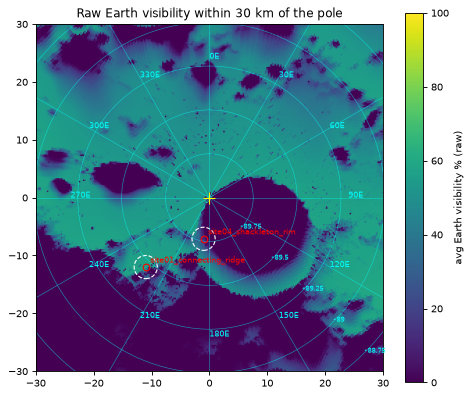

In [18]:
# Visual: raw Earth visibility around Site01/Site04 at 240 m with the two sites, plus 2 km circles
fig, ax = plt.subplots(figsize=(7, 6))
r = 30_000
win = rasterio.windows.from_bounds(-r, -r, r, r, ev_raw.transform)
a = ev_raw.read(1, window=win, masked=True)
b = rasterio.windows.bounds(win, ev_raw.transform)
im = ax.imshow(100 * a, extent=[v / 1e3 for v in (b[0], b[2], b[1], b[3])], cmap="viridis", vmin=0, vmax=100)
graticule(ax, (-30, 30, -30, 30), lat_step=0.25); sites(ax, (-30, 30, -30, 30), "red")
for k in ("site01_connecting_ridge", "site04_shackleton_rim"):
    x, y = sp_xy(*SITES[k]); ax.add_patch(plt.Circle((x / 1e3, y / 1e3), 2, fill=False, color="w", ls="--"))
plt.colorbar(im, label="avg Earth visibility % (raw)"); ax.set_title("Raw Earth visibility within 30 km of the pole")
plt.show()
ev_raw.close(); wac_raw.close()

## 6. Implications for the app

**Use Trek as a basemap, not as the source of numbers.**

| need | recommended Trek source | how |
|---|---|---|
| polar imagery basemap | `LRO_WAC_Mosaic_SPole60_100m_v02` (SP), `LRO_WAC_Mosaic_Global_303ppd_v02` (EQ, non-polar sites) | WMTS straight in the browser (e.g. OpenLayers with a custom polar-stereographic projection and the tile grid above) |
| near-pole relief | `LRO_LOLA_Shade_SPole875_5mp_v04` (to 87.5°S, 16.7 m tiles) | WMTS overlay |
| comms context layer | `ClrAVGVISIB_*_EARTH_SP` (colorized) for display. For **numbers**, the raw `AVGVISIB_85S_060M` / `65S_240M` from `data/stream`, pre-sampled offline at candidate sites | ship a small precomputed table, never the 100–244 MB GeoTIFFs |
| lighting context | `WAC_POLE_ILL_PCT_SOUTH_100M` (88–90°S only) for display; raw file (1.6 MB) for numbers | static % lit, used to sanity-check our computed sunlit fraction |
| hazards | `PSR_SP` (vector), `ColorSlope_*_5m` / `LOLA_RGB_Slope_*` | overlays only. Get slope values from PGDA 5 m float DEMs |
| site context | `A3_Named_regions_SP` (GeoJSON from `data/stream`) | vector overlay, easy to bundle (3.5 kB) |

* Trek gives **static long-term averages**. The app's date-specific Sun/Earth elevation needs ephemerides (Horizons) plus a horizon mask from a float DEM. The Trek averages are a useful **validation target**: a full 18.6-year run of our method at a site should land close to the raw `AVGVISIB` value.
* Never read physical values from tile pixels on the client. The stretches are undocumented and lossy, and the zoom levels stop short of native resolution.
* Coordinates: everything in SP is the IAU2000:30120 sphere stereographic, so `+proj=stere +lat_0=-90 +lon_0=0 +R=1737400` works directly with pyproj and proj4js. Vector downloads come in lon/lat (east-positive).
* Connector issues (reported, not fixed): the EQ pixel size is 3.67× too large. `mosaic()` uses the capabilities bbox, which can be smaller than the data (AVGVISIB_65S is cut at about 65°S). There is no downloader for raw/vector `data/stream` files.